# Visualize stage-1 track SSMs on RGB

Pick a clip window with `START_IDX` + `SEQ_LEN`, run a stage-1 SSM
(`initiate` / `predict` / `update`) on noisy oracle measurements from
`Label.csv`, and overlay **mean + covariance** on the real RGB frames.

Edit the control cell, then re-run from there. `TRACKER` selects from
`cv_kf`, `cv_akf`, `ca_akf`, `cv_pf`. All return `TrackState` (mean/cov;
PF also attaches particles). Adaptive filters learn `Q`/`R` online;
`ca_akf` uses a 6D CA state `[x,y,vx,vy,ax,ay]`.


In [5]:
from __future__ import annotations

import math
from typing import Any, Callable

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
import numpy as np

from horus.config import load_config
from horus.convert.frame_diff import load_rgb
from horus.data.index import index_clips
from horus.data.targets import scale_coords
from horus.track import TrackState, add_gaussian_noise, build_akf, build_ca_akf, build_kf, build_pf

# =============================================================================
# Controls — edit, then re-run this cell and below
# =============================================================================
GAME = "game1"
CLIP = "Clip1"
START_IDX =36          # first frame index in the clip
SEQ_LEN = 36       # number of frames to track / show
TRACKER = "cv_akf"      # "cv_kf" | "cv_akf" | "ca_akf" | "cv_pf"
SEED = 0                # noise RNG; None = fresh each run
NOISE_SIGMA = None      # px; None → tracker.r_meas
N_SIGMA = 3.0           # covariance ellipse / gate contour
NCOLS = 4               # RGB grid columns
# =============================================================================

cfg = load_config()
W = int(cfg["image"]["width"])
H = int(cfg["image"]["height"])
src_w = int(cfg["source"]["width"])
src_h = int(cfg["source"]["height"])
rng = np.random.default_rng(SEED)

def _build_pf(cfg):
    # Prefer notebook SEED for reproducible particle noise when set
    tcfg = dict(cfg.get("tracker") or {})
    if SEED is not None and tcfg.get("pf_seed") is None:
        tcfg["pf_seed"] = SEED
    return build_pf({**cfg, "tracker": tcfg})

TRACKER_BUILDERS: dict[str, Callable[[dict[str, Any]], Any]] = {
    "cv_kf": build_kf,
    "cv_akf": build_akf,
    "ca_akf": build_ca_akf,
    "cv_pf": _build_pf,
}
if TRACKER not in TRACKER_BUILDERS:
    raise KeyError(f"Unknown TRACKER={TRACKER!r}; choose from {sorted(TRACKER_BUILDERS)}")
tracker = TRACKER_BUILDERS[TRACKER](cfg)
sigma = float(NOISE_SIGMA) if NOISE_SIGMA is not None else float(getattr(tracker, "r_meas", 5.0))

clips = {c.key: c for c in index_clips(cfg["paths"]["raw_dataset"])}
key = f"{GAME}/{CLIP}"
if key not in clips:
    raise KeyError(f"Clip not found: {key}")
clip = clips[key]
end_idx = START_IDX + SEQ_LEN
if START_IDX < 0 or end_idx > clip.num_frames:
    raise IndexError(
        f"Window [{START_IDX}, {end_idx}) out of range for {key} "
        f"(n_frames={clip.num_frames})"
    )

paths = clip.frames[START_IDX:end_idx]
labels = clip.labels[START_IDX:end_idx]
true_xy = np.zeros((SEQ_LEN, 2), dtype=np.float64)
visible = np.zeros(SEQ_LEN, dtype=bool)
for t, lb in enumerate(labels):
    visible[t] = lb.visibility != 0
    true_xy[t] = scale_coords(lb.x, lb.y, src_w, src_h, W, H)

meas = add_gaussian_noise(true_xy, sigma=sigma, rng=rng)
rgbs = [load_rgb(str(p), W, H) for p in paths]

# Run SSM: initiate on first visible meas; invisible → predict-only
states: list[TrackState | None] = []
state: TrackState | None = None
for t in range(SEQ_LEN):
    if state is None:
        if visible[t]:
            state = tracker.initiate(meas[t])
        states.append(state)
        continue
    state = tracker.predict(state)
    state = tracker.update(state, meas[t] if visible[t] else None)
    states.append(state)

tracked = [s is not None for s in states]
n_vis = int(visible.sum())
print(
    f"{key}  frames[{START_IDX}:{end_idx}]  tracker={TRACKER}  "
    f"sigma={sigma:.1f}px  visible={n_vis}/{SEQ_LEN}  "
    f"initiated={any(tracked)}"
)
if n_vis == 0:
    print("No visible labels in window — bump START_IDX or SEQ_LEN.")
if TRACKER in ("cv_akf", "ca_akf"):
    print(
        f"akf learned  r≈{float(np.sqrt(0.5*(tracker.R[0,0]+tracker.R[1,1]))):.2f}px  "
        f"tr(Q)={float(np.trace(tracker.Q)):.3g}  updates={tracker._update_count}"
    )


game1/Clip1  frames[36:72]  tracker=cv_akf  sigma=5.0px  visible=36/36  initiated=True
akf learned  r≈6.22px  tr(Q)=193  updates=35


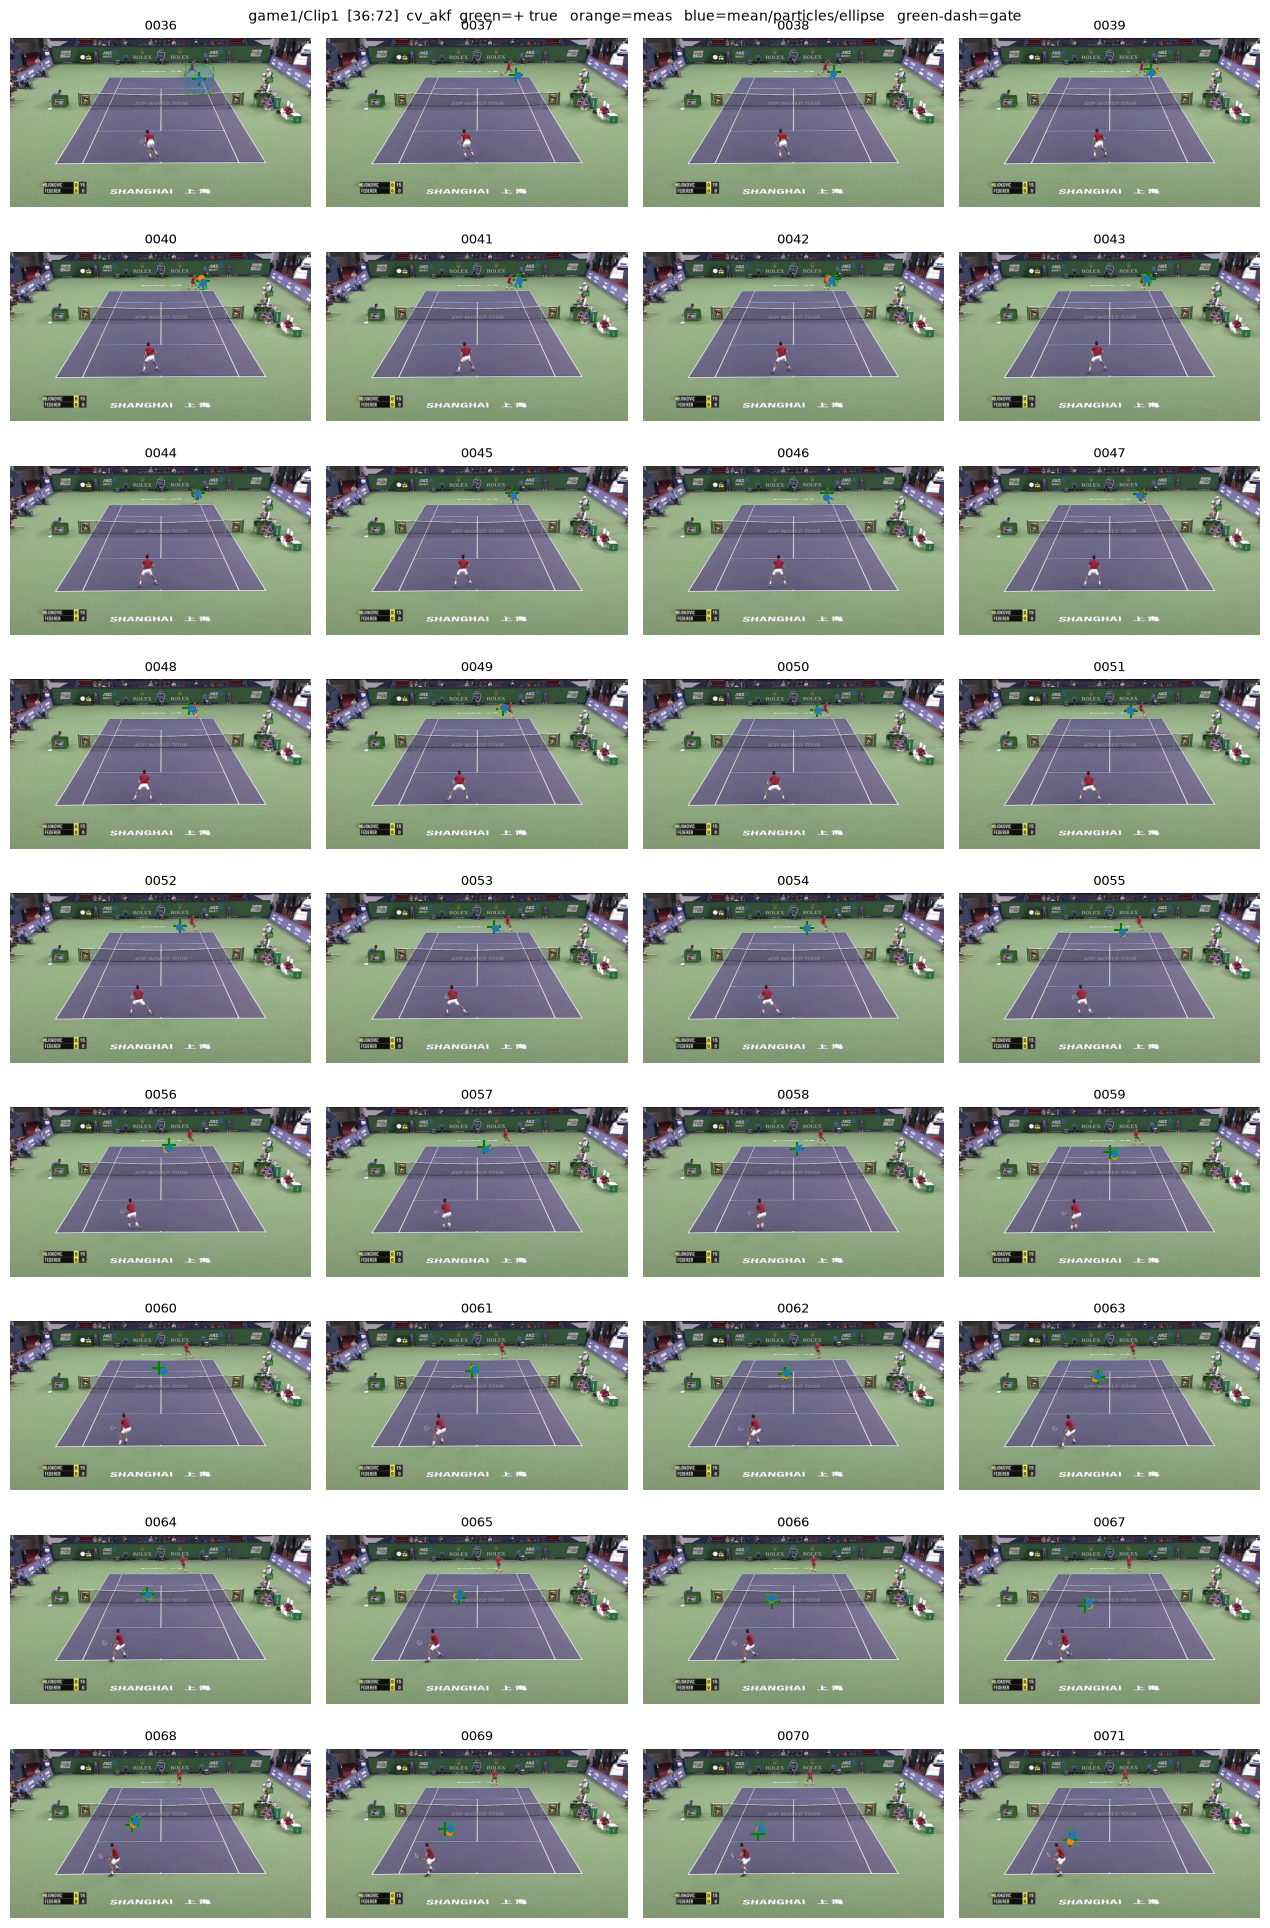

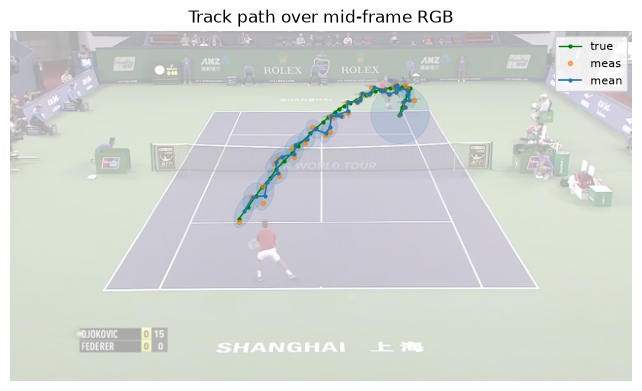

In [6]:
def cov_ellipse(mean_xy, cov_xy, n_sigma=3.0, **kwargs) -> Ellipse:
    mean_xy = np.asarray(mean_xy, dtype=np.float64).reshape(2)
    cov_xy = 0.5 * (np.asarray(cov_xy, dtype=np.float64).reshape(2, 2)
                    + np.asarray(cov_xy, dtype=np.float64).reshape(2, 2).T)
    vals, vecs = np.linalg.eigh(cov_xy)
    vals = np.clip(vals, 1e-12, None)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    angle = math.degrees(math.atan2(vecs[1, 0], vecs[0, 0]))
    return Ellipse(
        xy=(float(mean_xy[0]), float(mean_xy[1])),
        width=float(2 * n_sigma * np.sqrt(vals[0])),
        height=float(2 * n_sigma * np.sqrt(vals[1])),
        angle=float(angle),
        **kwargs,
    )


def draw_overlays(ax, t: int) -> None:
    ax.imshow(rgbs[t])
    ax.set_axis_off()
    fi = START_IDX + t
    ax.set_title(f"{fi:04d}", fontsize=9)
    if visible[t]:
        ax.plot(true_xy[t, 0], true_xy[t, 1], "g+", ms=10, mew=1.5, label="true")
        ax.plot(meas[t, 0], meas[t, 1], "o", color="C1", ms=4, label="meas")
    st = states[t]
    if st is None:
        return
    ax.plot(st.mean[0], st.mean[1], "o", color="C0", ms=4, label="mean")
    if st.particles is not None:
        ax.scatter(
            st.particles[:, 0],
            st.particles[:, 1],
            s=4,
            c="C0",
            alpha=0.15,
            linewidths=0,
            zorder=2,
        )
    # velocity tick
    ax.annotate(
        "",
        xy=(st.mean[0] + 0.12 * st.mean[2], st.mean[1] + 0.12 * st.mean[3]),
        xytext=(st.mean[0], st.mean[1]),
        arrowprops=dict(arrowstyle="->", color="C0", lw=1.2),
    )
    ax.add_patch(
        cov_ellipse(
            st.mean[:2],
            st.cov[:2, :2],
            n_sigma=N_SIGMA,
            facecolor="C0",
            edgecolor="C0",
            alpha=0.25,
            lw=1.2,
        )
    )
    if hasattr(tracker, "gate_window"):
        x0, y0, x1, y1 = tracker.gate_window(st, n_sigma=N_SIGMA)
        ax.add_patch(
            mpatches.Rectangle(
                (x0, y0),
                x1 - x0,
                y1 - y0,
                fill=False,
                edgecolor="C2",
                ls="--",
                lw=1.0,
            )
        )


nrows = int(math.ceil(SEQ_LEN / NCOLS))
fig, axes = plt.subplots(nrows, NCOLS, figsize=(3.2 * NCOLS, 2.2 * nrows))
axes = np.atleast_2d(axes)
for t in range(nrows * NCOLS):
    ax = axes[t // NCOLS, t % NCOLS]
    if t < SEQ_LEN:
        draw_overlays(ax, t)
    else:
        ax.set_axis_off()

fig.suptitle(
    f"{key}  [{START_IDX}:{end_idx}]  {TRACKER}  "
    f"green=+ true   orange=meas   blue=mean/particles/ellipse   green-dash=gate",
    fontsize=10,
)
fig.tight_layout()
plt.show()

# Compact path summary (same window)
fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(rgbs[SEQ_LEN // 2], alpha=0.35)
ax.plot(true_xy[visible, 0], true_xy[visible, 1], "g.-", ms=4, lw=1, label="true")
ax.plot(meas[visible, 0], meas[visible, 1], "o", color="C1", ms=3, alpha=0.6, label="meas")
est = np.array([s.mean[:2] for s in states if s is not None])
if len(est):
    ax.plot(est[:, 0], est[:, 1], "C0.-", ms=4, lw=1.2, label="mean")
    for t, st in enumerate(states):
        if st is None:
            continue
        ax.add_patch(
            cov_ellipse(
                st.mean[:2],
                st.cov[:2, :2],
                n_sigma=N_SIGMA,
                facecolor="C0",
                edgecolor="C0",
                alpha=0.12,
                lw=0.7,
            )
        )
ax.set_xlim(0, W)
ax.set_ylim(H, 0)
ax.set_title("Track path over mid-frame RGB")
ax.legend(loc="best", fontsize=8)
ax.set_axis_off()
fig.tight_layout()
plt.show()


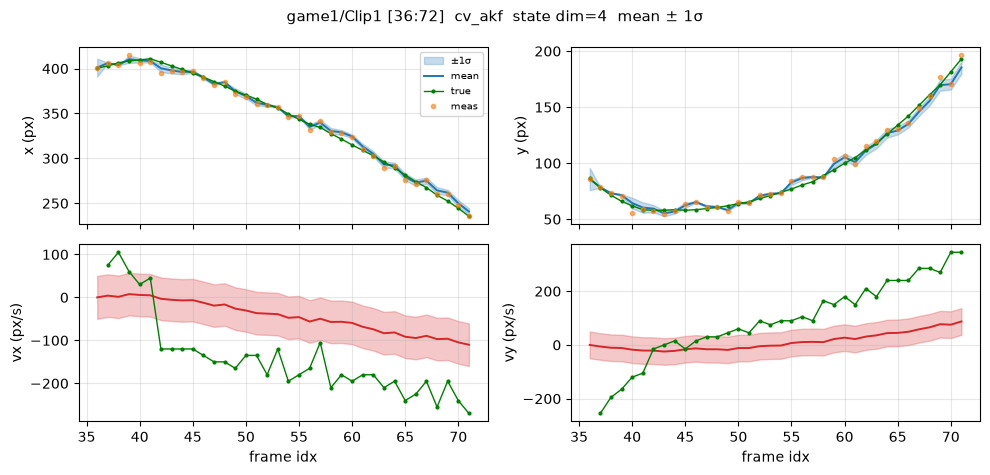

In [7]:
# Position / velocity (/ accel) uncertainty over the window (diagonal std of P)
ts = np.arange(START_IDX, end_idx)
state_dim = next((s.dim for s in states if s is not None), 4)
means = np.full((SEQ_LEN, state_dim), np.nan)
stds = np.full((SEQ_LEN, state_dim), np.nan)
for t, st in enumerate(states):
    if st is None:
        continue
    means[t] = st.mean
    stds[t] = np.sqrt(np.clip(np.diag(st.cov), 0, None))

labels_uv = ["x (px)", "y (px)", "vx (px/s)", "vy (px/s)"]
units_truth = [true_xy[:, 0], true_xy[:, 1], None, None]
meas_series = [meas[:, 0], meas[:, 1], None, None]
if state_dim >= 6:
    labels_uv += ["ax (px/s²)", "ay (px/s²)"]
    units_truth += [None, None]
    meas_series += [None, None]

true_vel = np.full((SEQ_LEN, 2), np.nan)
true_acc = np.full((SEQ_LEN, 2), np.nan)
dt_t = float(getattr(tracker, "dt", 1 / 30))
if visible.any():
    for t in range(1, SEQ_LEN):
        if visible[t] and visible[t - 1]:
            true_vel[t] = (true_xy[t] - true_xy[t - 1]) / dt_t
    for t in range(2, SEQ_LEN):
        if visible[t] and visible[t - 1] and visible[t - 2]:
            true_acc[t] = (true_vel[t] - true_vel[t - 1]) / dt_t

nrows = 3 if state_dim >= 6 else 2
ncols = 2
fig, axes = plt.subplots(nrows, ncols, figsize=(10, 2.4 * nrows), sharex=True)
axes_flat = np.atleast_1d(axes).ravel()

series = [
    (0, true_xy[:, 0], meas[:, 0], "C0"),
    (1, true_xy[:, 1], meas[:, 1], "C0"),
    (2, true_vel[:, 0], None, "C3"),
    (3, true_vel[:, 1], None, "C3"),
]
if state_dim >= 6:
    series += [
        (4, true_acc[:, 0], None, "C4"),
        (5, true_acc[:, 1], None, "C4"),
    ]

for ax, (i, truth, z, band_c) in zip(axes_flat, series):
    mu, sd = means[:, i], stds[:, i]
    ax.fill_between(ts, mu - sd, mu + sd, color=band_c, alpha=0.25, label="±1σ")
    ax.plot(ts, mu, color=band_c, lw=1.4, label="mean")
    if i < 2:
        ax.plot(ts[visible], truth[visible], "g.-", ms=4, lw=1, label="true")
        if z is not None:
            ax.plot(ts[visible], z[visible], "o", color="C1", ms=3, alpha=0.6, label="meas")
    else:
        ax.plot(ts, truth, "g.-", ms=4, lw=1, label="true Δ")
    ax.set_ylabel(labels_uv[i])
    ax.grid(True, alpha=0.3)

axes_flat[0].legend(loc="best", fontsize=7)
for ax in axes_flat[-2:]:
    ax.set_xlabel("frame idx")
fig.suptitle(
    f"{key} [{START_IDX}:{end_idx}]  {TRACKER}  state dim={state_dim}  mean ± 1σ",
    fontsize=11,
)
fig.tight_layout()
plt.show()


In [8]:
# Average absolute error vs label-derived truth for every estimated state component
dt_t = float(getattr(tracker, "dt", 1.0 / 30.0))
state_dim = next((s.dim for s in states if s is not None), 4)

# Build GT kinematics from visible label positions (finite differences)
gt = np.full((SEQ_LEN, state_dim), np.nan)
gt[:, :2] = true_xy
for t in range(1, SEQ_LEN):
    if visible[t] and visible[t - 1]:
        gt[t, 2:4] = (true_xy[t] - true_xy[t - 1]) / dt_t
if state_dim >= 6:
    for t in range(2, SEQ_LEN):
        if np.isfinite(gt[t, 2:4]).all() and np.isfinite(gt[t - 1, 2:4]).all():
            gt[t, 4:6] = (gt[t, 2:4] - gt[t - 1, 2:4]) / dt_t

est = np.full((SEQ_LEN, state_dim), np.nan)
for t, st in enumerate(states):
    if st is not None:
        est[t] = st.mean

comp_names = ["x", "y", "vx", "vy"] + (["ax", "ay"] if state_dim >= 6 else [])
comp_units = ["px", "px", "px/s", "px/s"] + (["px/s²", "px/s²"] if state_dim >= 6 else [])

print(f"{TRACKER}  {key}[{START_IDX}:{end_idx}]  mean |error| over valid frames")
rows = []
for i, (name, unit) in enumerate(zip(comp_names, comp_units)):
    valid = np.isfinite(est[:, i]) & np.isfinite(gt[:, i])
    if i < 2:
        # position: also require label visibility
        valid &= visible
    n = int(valid.sum())
    if n == 0:
        mae = float("nan")
        rmse = float("nan")
    else:
        err = est[valid, i] - gt[valid, i]
        mae = float(np.mean(np.abs(err)))
        rmse = float(np.sqrt(np.mean(err**2)))
    rows.append((name, mae, rmse, n, unit))
    print(f"  {name:>2}:  MAE={mae:8.3f}  RMSE={rmse:8.3f}  n={n:3d}  ({unit})")

# Grouped vector errors (position / velocity / acceleration)
def _vec_rmse(cols: slice, require_vis: bool = False) -> tuple[float, int]:
    mask = np.isfinite(est[:, cols]).all(axis=1) & np.isfinite(gt[:, cols]).all(axis=1)
    if require_vis:
        mask &= visible
    n = int(mask.sum())
    if n == 0:
        return float("nan"), 0
    d = np.linalg.norm(est[mask][:, cols] - gt[mask][:, cols], axis=1)
    return float(np.mean(d)), n

pos_mae, n_pos = _vec_rmse(slice(0, 2), require_vis=True)
vel_mae, n_vel = _vec_rmse(slice(2, 4))
print(f"  pos ‖·‖:  mean={pos_mae:8.3f} px     n={n_pos:3d}")
print(f"  vel ‖·‖:  mean={vel_mae:8.3f} px/s   n={n_vel:3d}")
if state_dim >= 6:
    acc_mae, n_acc = _vec_rmse(slice(4, 6))
    print(f"  acc ‖·‖:  mean={acc_mae:8.3f} px/s²  n={n_acc:3d}")


cv_akf  game1/Clip1[36:72]  mean |error| over valid frames
   x:  MAE=   3.455  RMSE=   4.221  n= 36  (px)
   y:  MAE=   3.348  RMSE=   4.211  n= 36  (px)
  vx:  MAE= 112.930  RMSE= 117.435  n= 35  (px/s)
  vy:  MAE= 123.147  RMSE= 143.816  n= 35  (px/s)
  pos ‖·‖:  mean=   5.253 px     n= 36
  vel ‖·‖:  mean= 176.160 px/s   n= 35
